# Positional Encoding

## 1. Qual a função do  Positional Encoding?

Diferente dos RNNs, que são recorrentes e processam dados sequencias, a arquitetura dos Transformers permite processar os tokens em paralelo. Entretanto, essa arquitetura não incorpora por si só a informação sobre a posição de cada token na sequência.

> *"Como nosso modelo não contém recorrência nem convolução, para que ele possa fazer uso da ordem da sequência, precisamos inserir alguma informação sobre a posição relativa ou absoluta dos tokens na sequência."* <br> <br>- Paper Attention Is All You Need

Por conta disso é necessário que cada token carregue uma informação posicional para que o modelo possa interpretar essas relações nos tokens de entrada ou outros padrões úteis durante o treinamento.

Por exemplo, caso não consideremos a posição, as seguintes sentenças serão apresentar as mesmas representações iniciais para seus respectivos tokens:

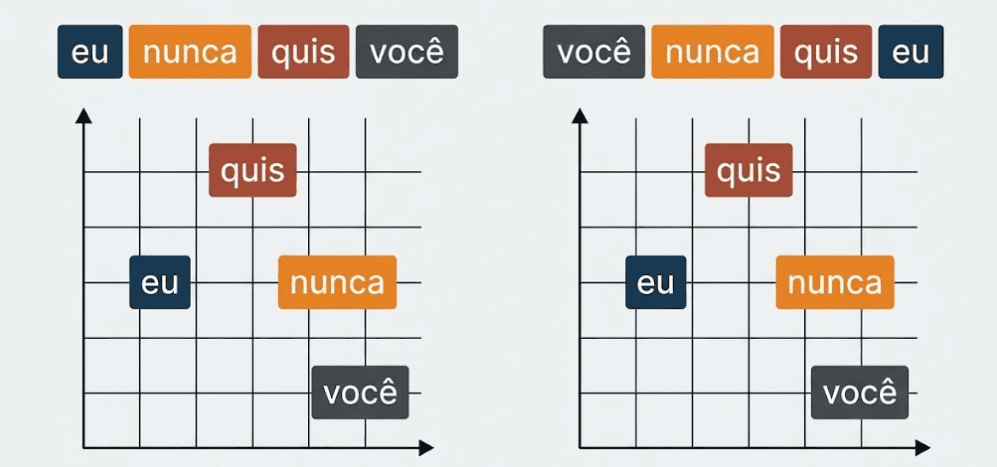

Perceba que a representação inicial dos seus tokens no espaço dos embeddings é exatamente a mesma sem a informação posicional.

O Positional Encoding cumpre exatamente esse papel, adicionar ao token informação que descreva sua localização/posição em uma sequência de tokens assinados por uma representação única ( ou quase ).

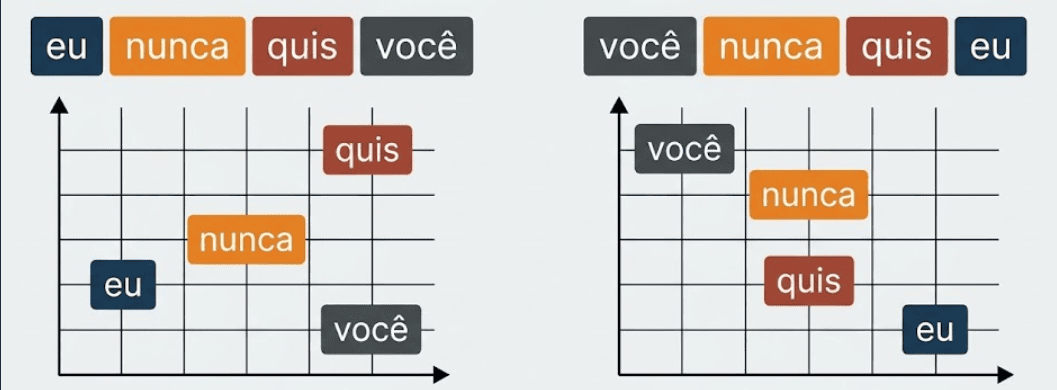


## 2. Como calcular o Posional Encoding


Primeiramente, precisamos construir os vetores posicionais, que contêm informação sobre a posição de cada token e possuem a mesma dimensão dos embeddings de entrada.

[imagem da soma dos vetores]

Para gerar uma codificação diferente para cada posição, utilizaremos a função sinusoidal proposta no paper original do Transformer:

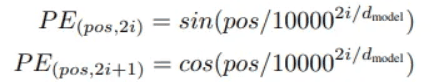

- Pos: posição do token na sequência
- d_model: numero de dimensões do modelo ( tamanho de cada vetor de embedding )
- i: índice utilizado para determinar as dimensões do vetor:
    - *PAR*: 2i 
    - *ÍMPAR*: 2i + 1 

### 2.1. Por que o denominador tem 10.000?

Como as funções sinusoidais são periódicas e cada dimensão utiliza uma frequência diferente, colocar um denominador como 10.000 permite distribuir essas frequências em diferentes escalas como vamos ver na seção 3.

Além disso, o denominador 10.000 faz com que tenhamos muitas possibilidades de codificação antes da periodicidade das funções senóides e cossenóides retornem um mesmo encoding posicional. Na verdade a janela de contexto do Transformers é muito menor do que isso.


### 2.2. Por que Seno e Cosseno?

- São funções periódicas;
- Retornam valores dentro do intervalo (-1, 1);
- Função contínua e suave;
- Utilizar frequências diferentes permite criar padrões posicionais variados;
 

### 2.3. Por que somar os vetores e não concatena-los?

Concatenar 2 vetores aumenta o número de dimensões e consequentemente aumenta o custo computacional. Ao somar os vetores, mantemos a mesma dimensão do embedding e adicionamos a informação posicional.

Além disso, ao decorrer do treinamento o modelo aprende a utilizar essas informações para identificar padrões relevantes sobre a sequência.

## 3. Uma visão Geral

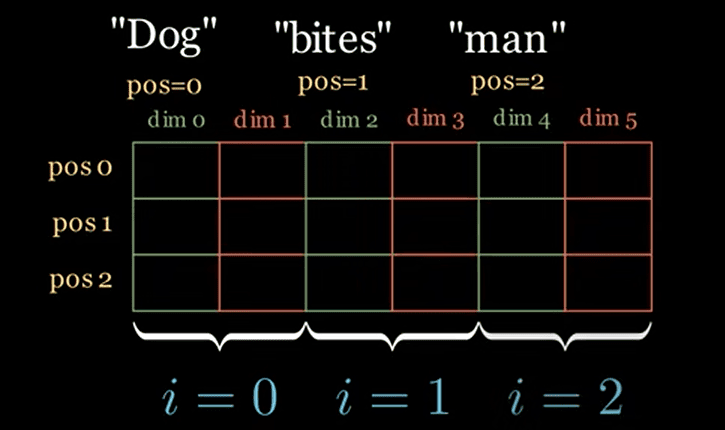

Considerando os 3 tokens de entrada como "Dog", "bites" e "man", cada token será representado por um embedding de 6 dimensões a nível didático.

Cada índice (i) determina um par de dimensões, onde a dimensão par recebe o resultado da função seno, e a dimensão ímpar recebe o resultado da função cosseno.

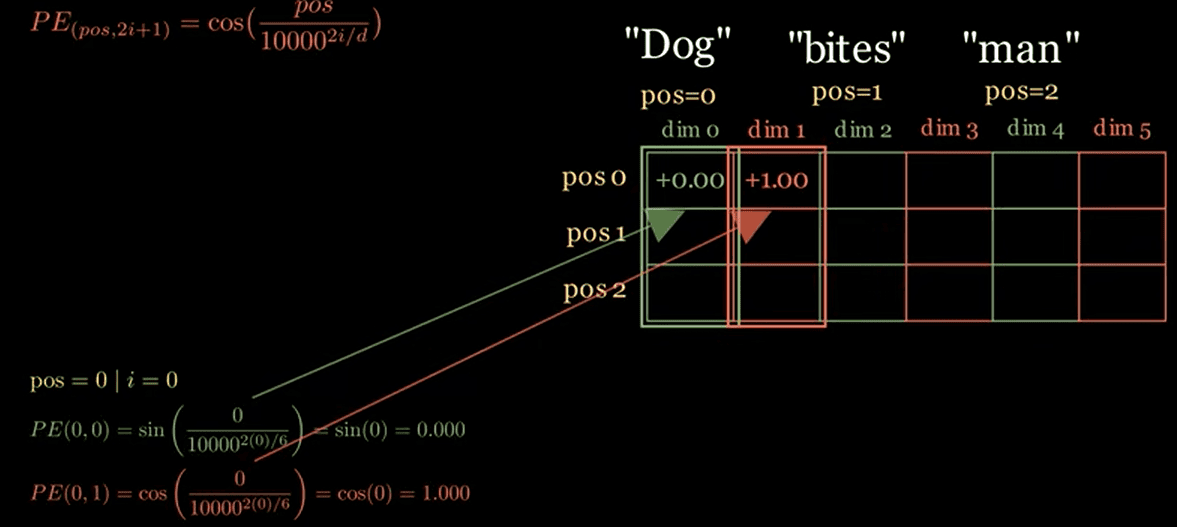

Ao calcular o positional encoding para pos = 0 no i = 0, temos os valores correspondentes a essa primeira posição. Vamos continuar percorrendo os índices:

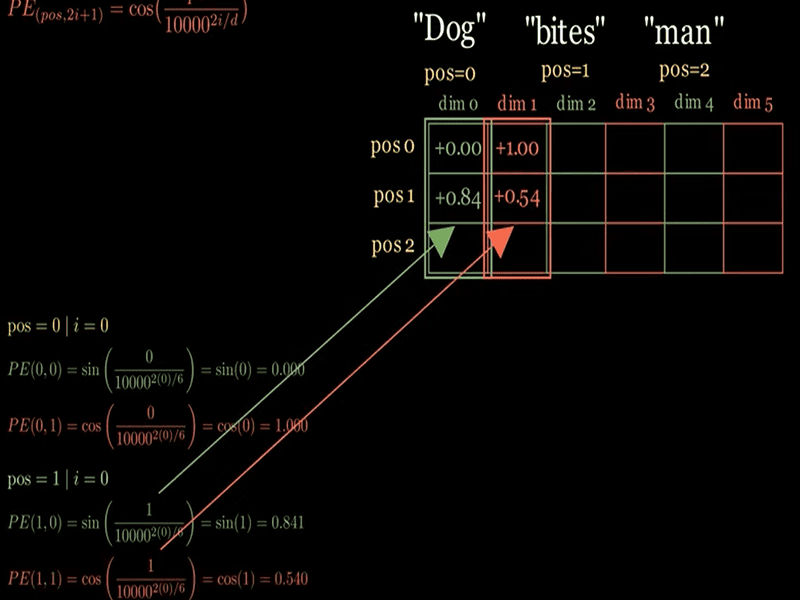

Perceba que ao mudar o valor de pos, os valores do POS também mudam, implicando em uma representação diferente. Vamos ver como se parece após mais algumas iterações:

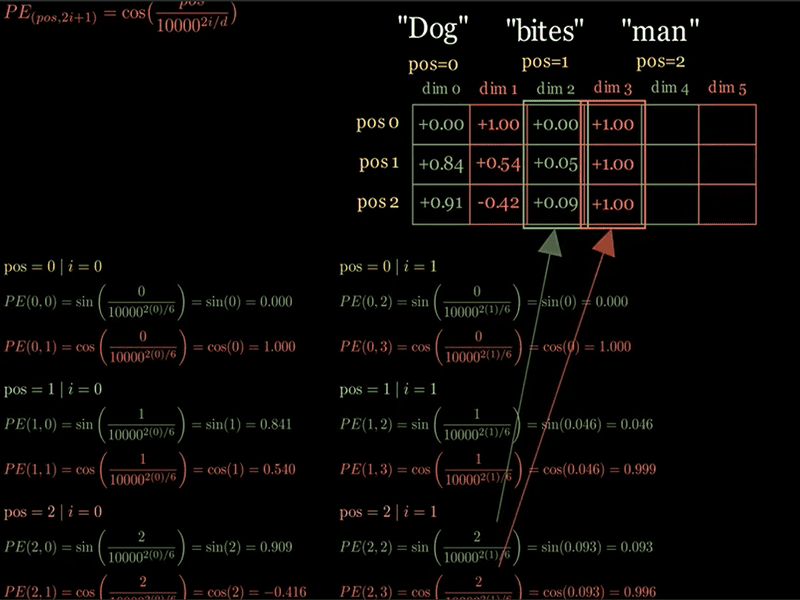

Veja como, nesse ponto, a codificação posicional de cada token já é completamente diferente ( e ainda faltam 2 dimensões a serem analisadas ). Por fim chegamos a seguinte codificação:

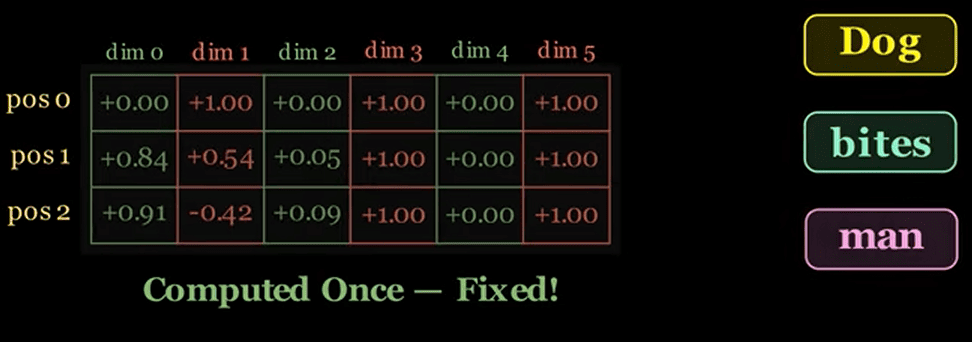

**Agora temos uma codificação posicional para cada posição na sequência!!**

*as imagens acima foram extraídas do vídeo: <br> "Why Transformers Need Positional Encoding | Sin & Cos Explained Visually"*

## 4. Positional Encoding x Positional Embedding

- **POSITIONAL ENCODING:** 
    - Geralmente se refere a uma função fixa ou deterministica, calculada por uma função.
    - Esse método **não acrescenta novos parâmetros ao modelo** quando utiliza a abordagem sinusoidal.
    
- **POSITIONAL EMBEDDING:**
    - Geralmente se refere a representações posicionais aprendidas por meio de parametros traináveis.
    - Abordagem muito utilizada em diversos modelos, incluindo algumas implementações de GPT e BERT.
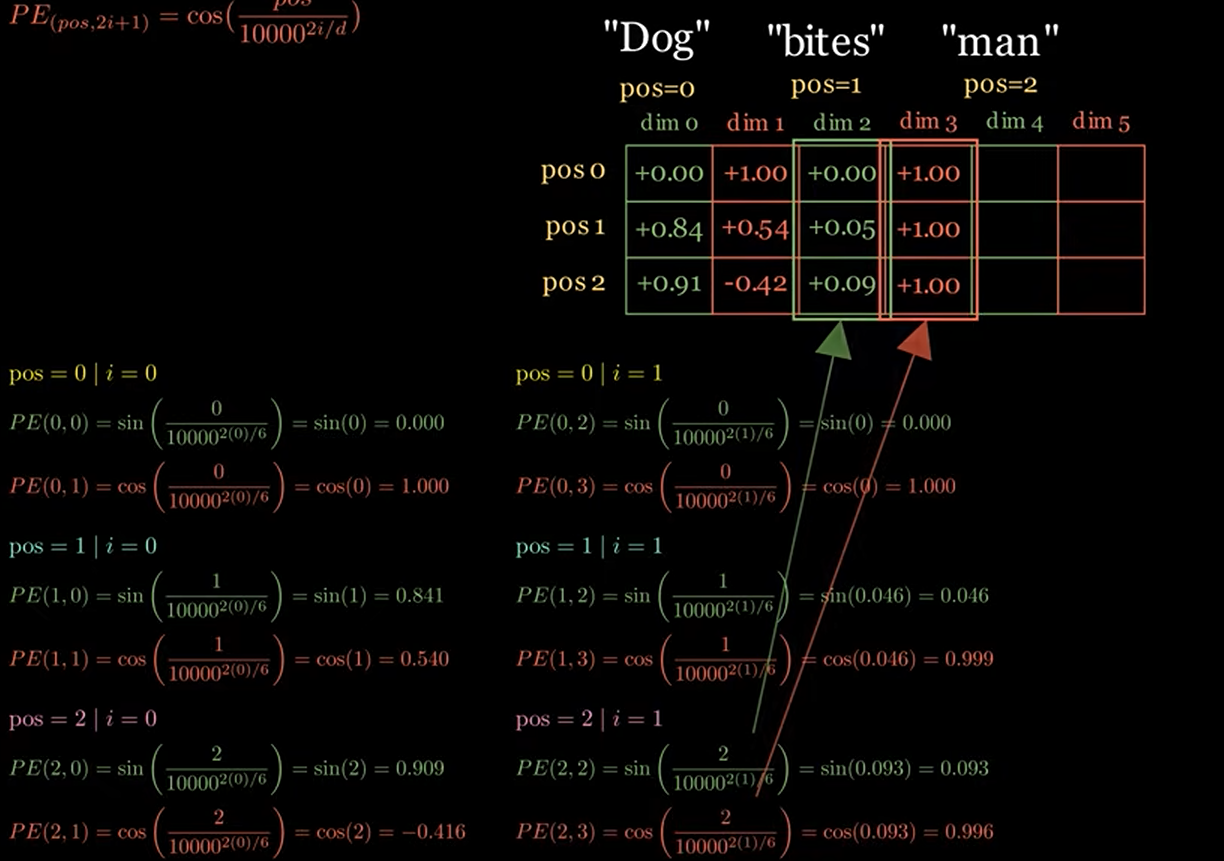
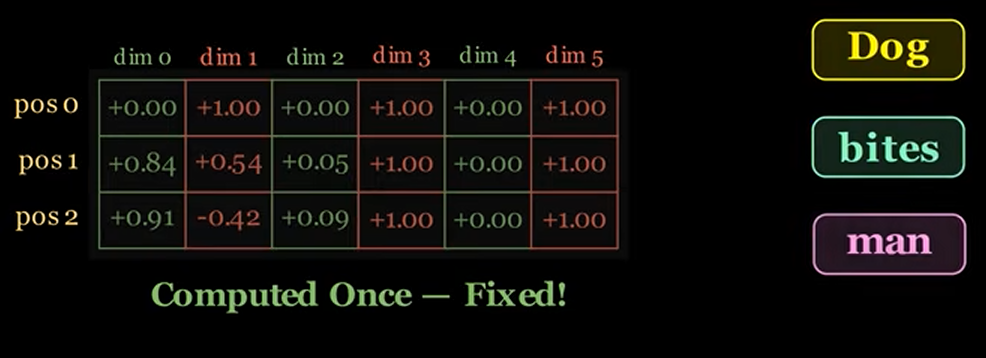

In [1]:
import torch.nn as nn
import torch

In [ ]:
class PositionalEncoding(nn.Module):
    def __init__(
        self,
        max_len: int,
        d_model: int,
        device: torch.device | None = None,
        dropout: float = 0.1,
    ):
        
        super().__init__()
        self.max_len = max_len
        self.dropout = nn.Dropout(dropout)

    # -----------------------------------------------

        pos_matrix = (
            torch.arange(
                0,
                max_len
            ).unsqueeze(1) #[L, 1]
        ).to(device) 

        # matriz que deve receber apenas o número das posições que vamos códificar
        # esse arrange cria um tensor unididmensional que parte do elemento 0 até max_len - 1
        # .unsqueeze(1) transforma o tensor de [L] para [L, 1]
        #
        # Exemplo para max_len = 6:
        # Output: tensor([[0],
        #                 [1],
        #                 [2],
        #                 [3],
        #                 [4],
        #                 [5]])

    # ----------------------------------------------

        #criando matriz que vai receber os positional encodings
        pe = torch.zeros(
                    max_len,
                    d_model
                ).to(device) # [L, D]

        # linha  -> posição na sequencia
        # coluna -> dimensão do encoding
 
    # ----------------------------------------------

        # 2i / d_model
        exp_div_term = (
                torch.arange(0, d_model, 2) # 2i 
                /d_model
                
            ).to(device)

        #10000^(2i/d_model)
        div_term = (
            10000.0 ** exp_div_term
        ).to(device)

        # Exemplo de div_term para d_model = 6:
        # Output: tensor([1.0000e+00, 4.6416e+02, 2.1544e+05])
        # esses valores que alteram o denominador a seguir e geram períodos diferentes
    
    # ------------------------------------------------

        
        pe[:, 0::2] = torch.sin(pos_matrix / div_term) #aplicando seno aos pares        
        pe[:, 1::2] = torch.cos(pos_matrix / div_term) #aplicando cosseno nos ímpares

        pe = pe.unsqueeze(0) #padrão esperado pelo embedding de [B, L, D]

        #levar self.pe para buffer, pois ele não será  treinado. 
        self.register_buffer(
            "pe", pe
        )

    def forward(self, x): # esse x represneta a matriz de embeddings
        _, seq_len, _ = x.shape

        if seq_len > self.max_len:
            raise ValueError(f"tamanho da sequencia ({seq_len}) maior do que o maximo permitido: {self.max_len}")

        #somando informação posicional a todos os tokens
        x = x + self.pe[:, :seq_len, :] 
        # [:, :seq_len, :] -> [sobre todos os batches, até o tamanho da sequencia de input, sobre todas as dimensões]
        
        return self.dropout(x)

